# Task 2: California Housing Price Prediction (OLS vs Ridge vs Lasso)

**Goal:** predict the median house value of a California district from its census features, and compare three linear models: Ordinary Least Squares (OLS), Ridge (L2) and Lasso (L1), using RMSE, MAE and R².

**Dataset:** California Housing (20,640 districts, 8 features). The target `MedHouseVal` is in units of $100,000.

**Steps:** EDA, missing values, correlation and multicollinearity check, interaction features, scaling, hyper-parameter tuning with GridSearchCV, metrics, predicted-vs-actual and residual plots.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the data

In [2]:
df = fetch_california_housing(as_frame=True).frame
print("Shape:", df.shape)
df.head()

Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 3. Exploratory data analysis

In [3]:
print(df.describe().T.round(2))
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

               count     mean      std     min     25%      50%      75%  \
MedInc       20640.0     3.87     1.90    0.50    2.56     3.53     4.74   
HouseAge     20640.0    28.64    12.59    1.00   18.00    29.00    37.00   
AveRooms     20640.0     5.43     2.47    0.85    4.44     5.23     6.05   
AveBedrms    20640.0     1.10     0.47    0.33    1.01     1.05     1.10   
Population   20640.0  1425.48  1132.46    3.00  787.00  1166.00  1725.00   
AveOccup     20640.0     3.07    10.39    0.69    2.43     2.82     3.28   
Latitude     20640.0    35.63     2.14   32.54   33.93    34.26    37.71   
Longitude    20640.0  -119.57     2.00 -124.35 -121.80  -118.49  -118.01   
MedHouseVal  20640.0     2.07     1.15    0.15    1.20     1.80     2.65   

                  max  
MedInc          15.00  
HouseAge        52.00  
AveRooms       141.91  
AveBedrms       34.07  
Population   35682.00  
AveOccup      1243.33  
Latitude        41.95  
Longitude     -114.31  
MedHouseVal      5.00  

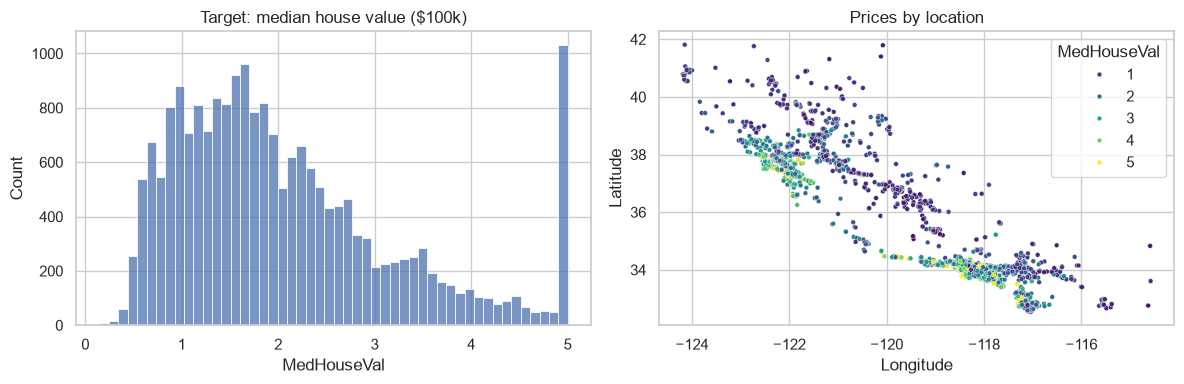

Rows at the price cap (5.0): 992


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["MedHouseVal"], bins=50, ax=axes[0])
axes[0].set_title("Target: median house value ($100k)")
sns.scatterplot(data=df.sample(3000, random_state=RANDOM_STATE), x="Longitude", y="Latitude",
                hue="MedHouseVal", palette="viridis", s=12, ax=axes[1])
axes[1].set_title("Prices by location")
plt.tight_layout(); plt.show()
print("Rows at the price cap (5.0):", (df["MedHouseVal"] >= 5.0).sum())

**Note on missing values.** This version of the dataset has no missing values, but the pipeline below still contains a `SimpleImputer(strategy="median")` step, so the model would handle nulls if they appeared. The imputer is fitted on the training data only.

**Note on the price cap.** The target is capped at 5.0 ($500,000). Those districts will show up as a diagonal line in the residual plot later.

## 4. Correlation heatmap and multicollinearity

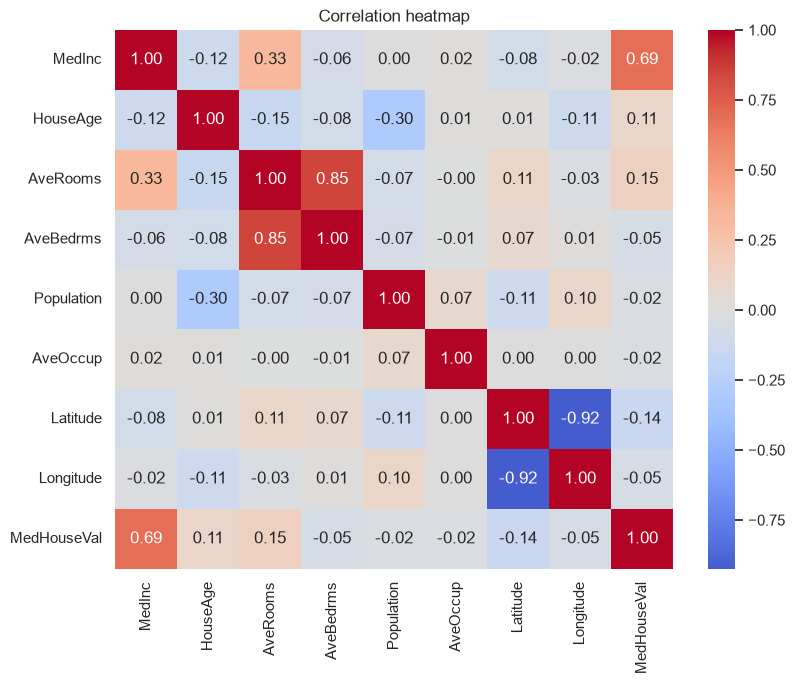

Correlation with the target:
 MedInc        0.688
AveRooms      0.152
HouseAge      0.106
AveOccup     -0.024
Population   -0.025
Longitude    -0.046
AveBedrms    -0.047
Latitude     -0.144
Name: MedHouseVal, dtype: float64


In [5]:
corr = df.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

print("Correlation with the target:\n", corr["MedHouseVal"].drop("MedHouseVal").sort_values(ascending=False).round(3))

**Variance Inflation Factor (VIF)** measures multicollinearity: how well one feature can be predicted from all the others. A VIF above about 5 to 10 is a warning sign. Ridge and Lasso are designed to cope with this problem.

In [6]:
def vif_table(frame):
    rows = []
    for col in frame.columns:
        others = frame.drop(columns=col)
        r2 = LinearRegression().fit(others, frame[col]).score(others, frame[col])
        rows.append((col, 1 / (1 - r2)))
    return pd.DataFrame(rows, columns=["feature", "VIF"]).sort_values("VIF", ascending=False).round(2)

features = df.drop(columns="MedHouseVal")
vif_table(features)

,feature,VIF
6,Latitude,9.30
7,Longitude,8.96
2,AveRooms,8.34
3,AveBedrms,6.99
0,MedInc,2.50
1,HouseAge,1.24
4,Population,1.14
5,AveOccup,1.01


## 5. Feature engineering (interaction features)

In [7]:
fe = df.copy()
fe["BedrmsRatio"]    = fe["AveBedrms"] / fe["AveRooms"]      # share of rooms that are bedrooms
fe["RoomsPerPerson"] = fe["AveRooms"] / fe["AveOccup"]       # space per resident
fe["Income_x_Rooms"] = fe["MedInc"] * fe["AveRooms"]         # richer areas with bigger homes
fe["Income_x_Age"]   = fe["MedInc"] * fe["HouseAge"]
fe["Lat_x_Lon"]      = fe["Latitude"] * fe["Longitude"]      # coarse location interaction

new_cols = ["BedrmsRatio", "RoomsPerPerson", "Income_x_Rooms", "Income_x_Age", "Lat_x_Lon"]
print(fe[new_cols + ["MedHouseVal"]].corr()["MedHouseVal"].drop("MedHouseVal").round(3))
fe.head()

BedrmsRatio      -0.256
RoomsPerPerson    0.209
Income_x_Rooms    0.555
Income_x_Age      0.589
Lat_x_Lon         0.105
Name: MedHouseVal, dtype: float64


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,BedrmsRatio,RoomsPerPerson,Income_x_Rooms,Income_x_Age,Lat_x_Lon
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526,0.146591,2.732919,58.144254,341.3332,-4630.0724
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585,0.155797,2.956685,51.785271,174.3294,-4627.2492
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521,0.129516,2.957661,60.150315,377.3848,-4626.7840
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413,0.184458,2.283154,32.827897,293.4412,-4627.1625
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422,0.172096,2.879646,24.161264,200.0024,-4627.1625


## 6. Train/test split (80/20)

In [8]:
X = fe.drop(columns="MedHouseVal")
y = fe["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (16512, 13)  Test: (4128, 13)


## 7. Baseline models: OLS, Ridge, Lasso

Each model sits in a `Pipeline` (impute, scale, fit). Putting the scaler inside the pipeline means it is fitted only on training data, and inside every cross-validation fold later. That avoids data leakage.

In [9]:
def make_pipe(model):
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler()),
                     ("model", model)])

def evaluate(name, pipe):
    pred = pipe.predict(X_test)
    return {"Model": name,
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "MAE": mean_absolute_error(y_test, pred),
            "R2": r2_score(y_test, pred)}

baseline = {"OLS": make_pipe(LinearRegression()),
            "Ridge (alpha=1)": make_pipe(Ridge(alpha=1.0)),
            "Lasso (alpha=0.01)": make_pipe(Lasso(alpha=0.01, max_iter=20000))}
for p in baseline.values():
    p.fit(X_train, y_train)

pd.DataFrame([evaluate(n, p) for n, p in baseline.items()]).round(4)

,Model,RMSE,MAE,R2
0,OLS,0.6770,0.4856,0.6502
1,Ridge (alpha=1),0.6772,0.4857,0.6501
2,Lasso (alpha=0.01),0.6826,0.4889,0.6445


## 8. Hyper-parameter tuning with GridSearchCV (5-fold)

In [10]:
ridge_grid = GridSearchCV(make_pipe(Ridge()),
                          {"model__alpha": np.logspace(-3, 3, 13)},
                          cv=5, scoring="neg_root_mean_squared_error")
lasso_grid = GridSearchCV(make_pipe(Lasso(max_iter=20000)),
                          {"model__alpha": np.logspace(-4, 0, 9)},
                          cv=5, scoring="neg_root_mean_squared_error")
ridge_grid.fit(X_train, y_train)
lasso_grid.fit(X_train, y_train)

print("Best Ridge alpha:", ridge_grid.best_params_["model__alpha"], " CV RMSE:", round(-ridge_grid.best_score_, 4))
print("Best Lasso alpha:", lasso_grid.best_params_["model__alpha"], " CV RMSE:", round(-lasso_grid.best_score_, 4))

Best Ridge alpha: 0.31622776601683794  CV RMSE: 0.6796
Best Lasso alpha: 0.001  CV RMSE: 0.6796


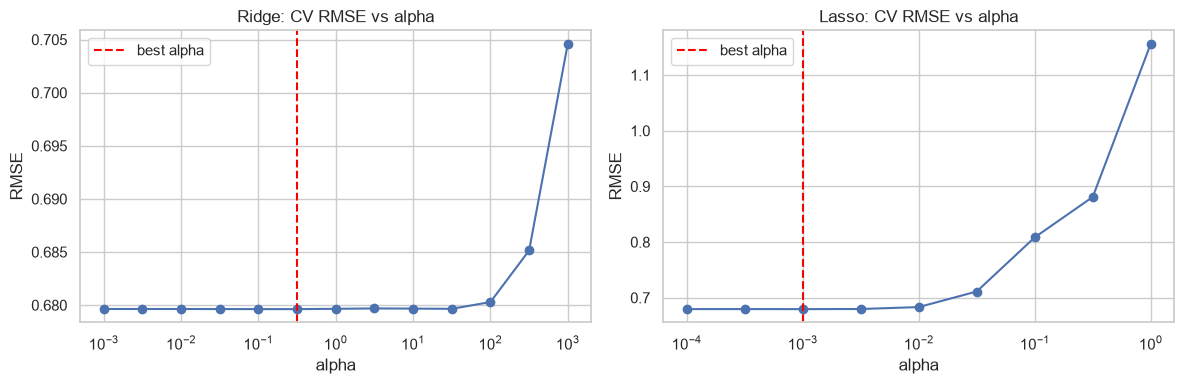

In [11]:
# CV error against alpha, to see where the sweet spot is
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, grid, title in [(axes[0], ridge_grid, "Ridge"), (axes[1], lasso_grid, "Lasso")]:
    alphas = grid.cv_results_["param_model__alpha"].data.astype(float)
    ax.semilogx(alphas, -grid.cv_results_["mean_test_score"], marker="o")
    ax.axvline(grid.best_params_["model__alpha"], color="red", ls="--", label="best alpha")
    ax.set_title(f"{title}: CV RMSE vs alpha"); ax.set_xlabel("alpha"); ax.set_ylabel("RMSE"); ax.legend()
plt.tight_layout(); plt.show()

## 9. Final comparison on the test set

In [12]:
final = {"OLS": baseline["OLS"],
         "Ridge (tuned)": ridge_grid.best_estimator_,
         "Lasso (tuned)": lasso_grid.best_estimator_}
results = pd.DataFrame([evaluate(n, p) for n, p in final.items()]).set_index("Model")
results.round(4)

,RMSE,MAE,R2
Model,,,
OLS,0.6770,0.4856,0.6502
Ridge (tuned),0.6771,0.4856,0.6502
Lasso (tuned),0.6768,0.4858,0.6505


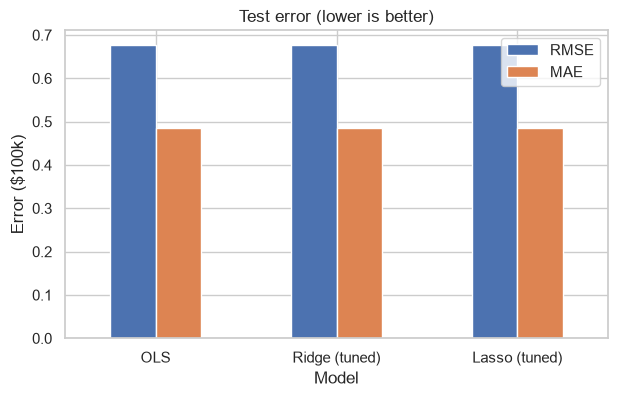

In [13]:
results[["RMSE", "MAE"]].plot(kind="bar", figsize=(7, 4), rot=0)
plt.title("Test error (lower is better)"); plt.ylabel("Error ($100k)")
plt.show()

## 10. What did Ridge and Lasso do to the coefficients?

In [14]:
coefs = pd.DataFrame({name: pipe.named_steps["model"].coef_ for name, pipe in final.items()},
                     index=X.columns)
print("Features Lasso set to exactly zero:", list(coefs.index[coefs["Lasso (tuned)"] == 0]))
coefs.round(3)

Features Lasso set to exactly zero: ['AveRooms', 'Lat_x_Lon']


,OLS,Ridge (tuned),Lasso (tuned)
MedInc,0.886,0.886,0.862
HouseAge,0.074,0.075,0.072
AveRooms,0.033,0.034,-0.000
AveBedrms,-0.304,-0.304,-0.276
Population,0.031,0.032,0.031
AveOccup,-0.021,-0.021,-0.020
Latitude,1.023,0.528,-0.862
Longitude,-1.346,-1.209,-0.811
BedrmsRatio,0.289,0.289,0.276
RoomsPerPerson,0.512,0.511,0.500


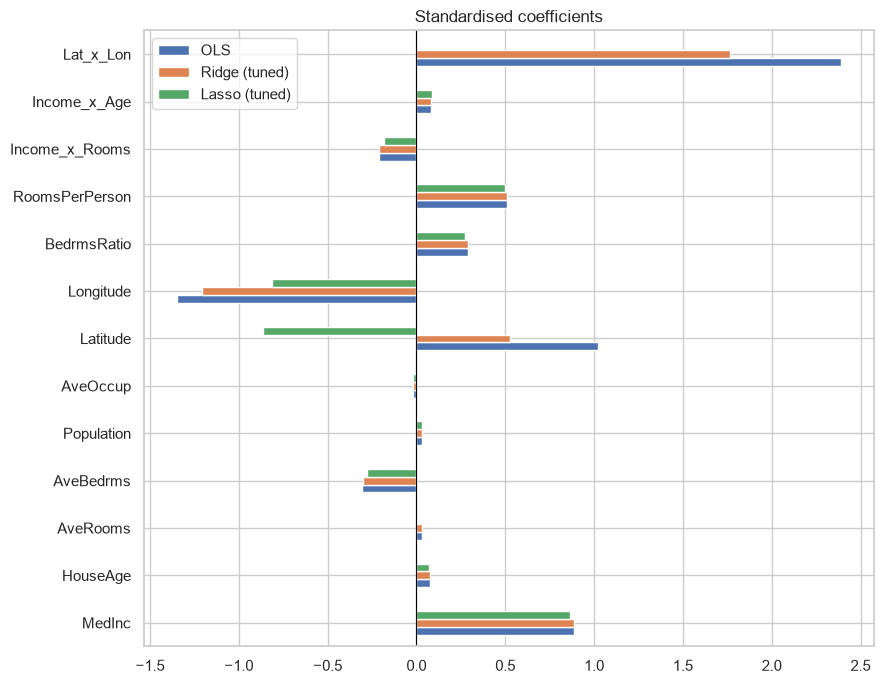

In [15]:
coefs.plot(kind="barh", figsize=(9, 7))
plt.title("Standardised coefficients"); plt.axvline(0, color="black", lw=0.8)
plt.tight_layout(); plt.show()

## 11. Predicted vs actual

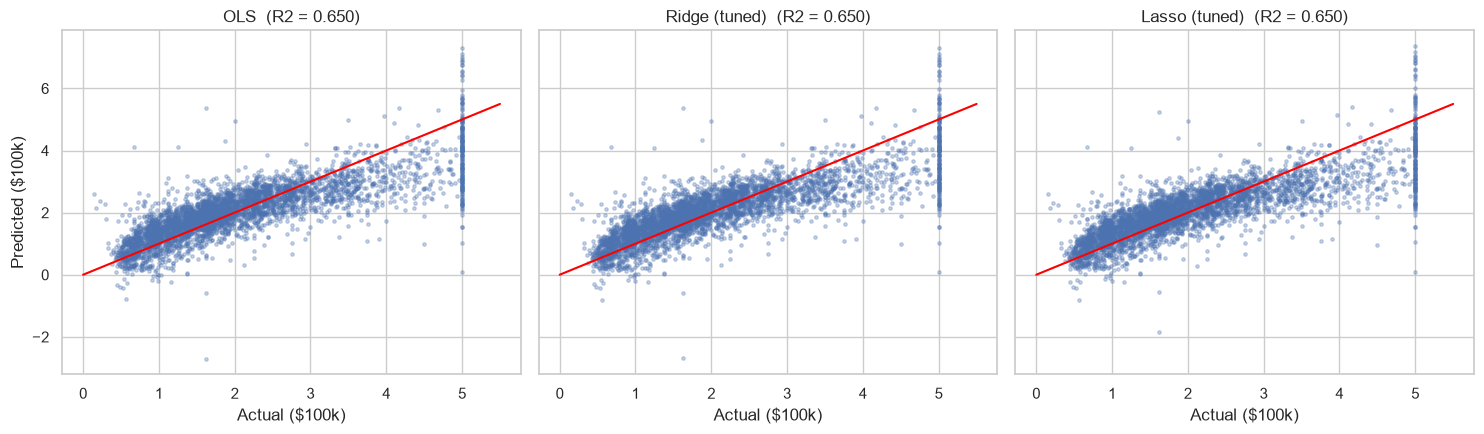

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
for ax, (name, pipe) in zip(axes, final.items()):
    pred = pipe.predict(X_test)
    ax.scatter(y_test, pred, s=6, alpha=0.3)
    lim = [0, 5.5]
    ax.plot(lim, lim, color="red", lw=1.5)
    ax.set_title(f"{name}  (R2 = {r2_score(y_test, pred):.3f})")
    ax.set_xlabel("Actual ($100k)")
axes[0].set_ylabel("Predicted ($100k)")
plt.tight_layout(); plt.show()

## 12. Residual analysis

Residual = actual minus predicted. In a good model residuals are centred on zero with no pattern.

Best model: Lasso (tuned) | mean residual: 0.0073 | std: 0.6768


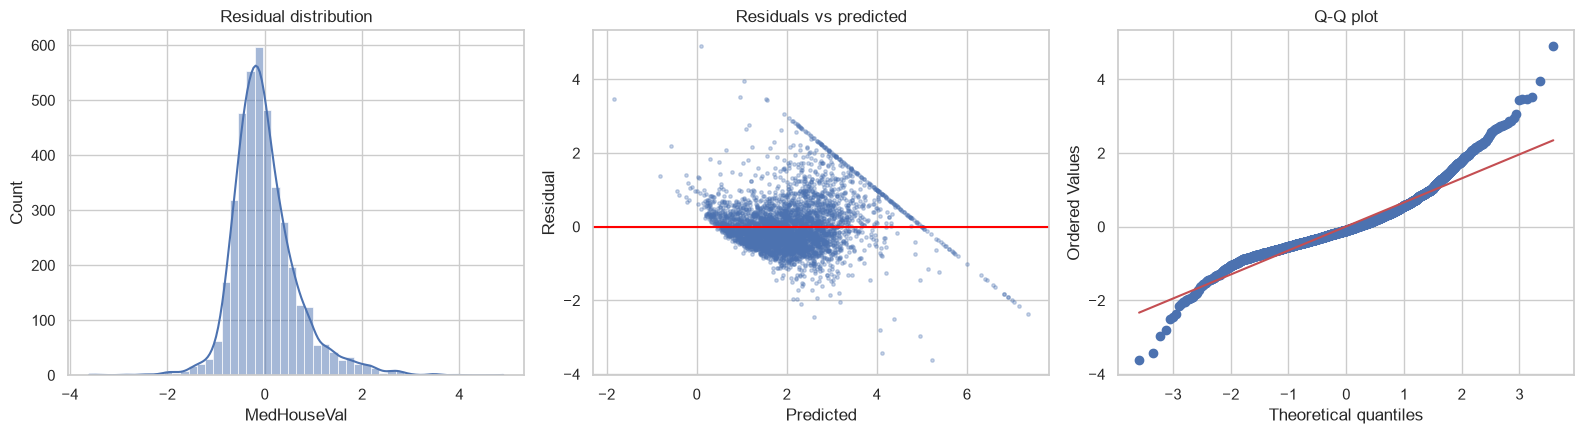

In [17]:
best_name = results["RMSE"].idxmin()
best_pred = final[best_name].predict(X_test)
resid = y_test - best_pred
print("Best model:", best_name, "| mean residual:", round(resid.mean(), 4), "| std:", round(resid.std(), 4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(resid, bins=50, kde=True, ax=axes[0]); axes[0].set_title("Residual distribution")
axes[1].scatter(best_pred, resid, s=6, alpha=0.3)
axes[1].axhline(0, color="red"); axes[1].set_title("Residuals vs predicted")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Residual")
from scipy import stats
stats.probplot(resid, dist="norm", plot=axes[2]); axes[2].set_title("Q-Q plot")
plt.tight_layout(); plt.show()

## 13. Conclusions

- **Best model:** Lasso (tuned) had the lowest test error (RMSE 0.6768, MAE 0.4858, R² 0.6505), but the three models are practically tied: OLS scored RMSE 0.6770 / R² 0.6502 and tuned Ridge RMSE 0.6771 / R² 0.6502.
- **Ridge vs OLS:** Their scores are nearly identical. After scaling, the data is well-conditioned and there are about 16,500 training rows, so shrinking the weights barely helps. The CV curves are flat until alpha becomes large, and the best alphas were small (Ridge about 0.3, Lasso about 0.003), so only light regularisation was needed.
- **Lasso:** It set AveRooms and Lat_x_Lon to exactly zero, so those features add little once the others are present. It also shrank the Latitude and Longitude weights.
- **Multicollinearity:** The heatmap shows Latitude and Longitude are strongly correlated (-0.92) and AveRooms and AveBedrms are correlated (0.85). OLS reacts with large, unstable, opposite-sign coefficients (Latitude +1.02, Longitude -1.35, Lat_x_Lon +2.39). Ridge shrinks these, and Lasso drops the redundant Lat_x_Lon feature and flips Latitude to a negative weight.
- **Feature engineering:** Income_x_Age (0.59) and Income_x_Rooms (0.56) correlate with price much more than the raw HouseAge (0.11) and AveRooms (0.15), so the interaction features helped the linear models. MedInc is the strongest single driver (correlation 0.69).
- **Residuals:** Residuals are centred on zero (mean 0.007, std 0.68) with a roughly bell-shaped distribution. The diagonal streak in the residual plot comes from the $500k price cap, and the Q-Q plot shows heavy tails: all three models under-predict the most expensive districts.
- **Limitation:** Linear models reach only about R² 0.65 here. Prices depend non-linearly on location, so a tree-based model such as Random Forest or Gradient Boosting would likely do better.